# 📈 Linear Regression: Three Ways to Fit a Line
### sklearn , Ordinary Least Squares (OLS) from Scratch . Gradient Descent from Scratch

---

**Dataset:** IBM Fuel Consumption & CO₂ Emissions  
**Goal:** Predict CO₂ emissions from engine size using three different implementations of Linear Regression


<a id='1'></a>
## 1. Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

<a id='2'></a>
## 2. Load & Explore the Dataset

In [2]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%202/data/FuelConsumptionCo2.csv"
df = pd.read_csv(url)
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [3]:
df.shape

(1067, 13)

In [4]:
df.columns

Index(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'ENGINESIZE', 'CYLINDERS',
       'TRANSMISSION', 'FUELTYPE', 'FUELCONSUMPTION_CITY',
       'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   object 
 2   MODEL                     1067 non-null   object 
 3   VEHICLECLASS              1067 non-null   object 
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   object 
 7   FUELTYPE                  1067 non-null   object 
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 108.5+ KB


In [6]:
df.describe().round(2)

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.00,1067.00,1067.00,1067.00,1067.00,1067.00,1067.00
mean,2014.0,3.35,5.79,13.30,9.47,11.58,26.44,256.23
std,0.0,1.42,1.80,4.10,2.79,3.49,7.47,63.37
min,2014.0,1.00,3.00,4.60,4.90,4.70,11.00,108.00
25%,2014.0,2.00,4.00,10.25,7.50,9.00,21.00,207.00
50%,2014.0,3.40,6.00,12.60,8.80,10.90,26.00,251.00
75%,2014.0,4.30,8.00,15.55,10.85,13.35,31.00,294.00
max,2014.0,8.40,12.00,30.20,20.50,25.80,60.00,488.00


In [7]:
df.isnull().sum()

MODELYEAR                   0
MAKE                        0
MODEL                       0
VEHICLECLASS                0
ENGINESIZE                  0
CYLINDERS                   0
TRANSMISSION                0
FUELTYPE                    0
FUELCONSUMPTION_CITY        0
FUELCONSUMPTION_HWY         0
FUELCONSUMPTION_COMB        0
FUELCONSUMPTION_COMB_MPG    0
CO2EMISSIONS                0
dtype: int64

In [8]:
df.columns

Index(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'ENGINESIZE', 'CYLINDERS',
       'TRANSMISSION', 'FUELTYPE', 'FUELCONSUMPTION_CITY',
       'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS'],
      dtype='object')

<a id='3'></a>
## 3. Visualisations

In [9]:

cols = ['MODELYEAR', 'ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_CITY',
       'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS']

In [10]:
df[cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   ENGINESIZE                1067 non-null   float64
 2   CYLINDERS                 1067 non-null   int64  
 3   FUELCONSUMPTION_CITY      1067 non-null   float64
 4   FUELCONSUMPTION_HWY       1067 non-null   float64
 5   FUELCONSUMPTION_COMB      1067 non-null   float64
 6   FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 7   CO2EMISSIONS              1067 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 66.8 KB


In [11]:
df_clean = df[cols].dropna().copy()

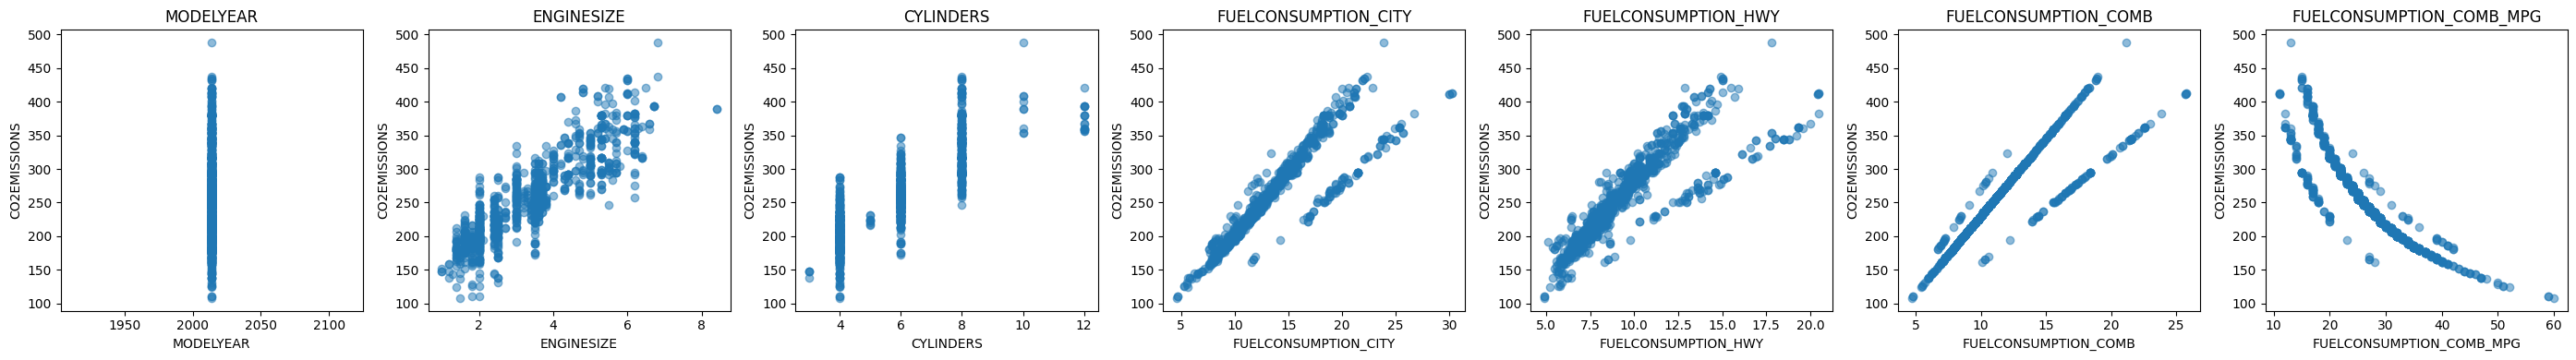

In [12]:
features = cols[:-1]

fig, axes = plt.subplots(1, len(features), figsize=(4*len(features), 4))

for ax, feat in zip(axes, features):
    ax.scatter(df_clean[feat], df_clean['CO2EMISSIONS'], alpha=0.5)
    ax.set_xlabel(feat)
    ax.set_ylabel('CO2EMISSIONS')
    ax.set_title(feat)

plt.tight_layout()
plt.show()

In [13]:
# Using 3 features so GD shows slight difference from OLS when not fully converged
X = df_clean[['MODELYEAR', 'ENGINESIZE', 'CYLINDERS',
              'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY',
              'FUELCONSUMPTION_COMB', 'FUELCONSUMPTION_COMB_MPG']]
y = df_clean['CO2EMISSIONS']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [14]:
X_train.shape

(853, 7)

<a id='4'></a>
## 4. Method 1 – sklearn `LinearRegression`

> sklearn uses **LAPACK's least-squares solver** (QR / SVD decomposition) internally — essentially the same closed-form OLS, but highly optimised.

In [15]:
sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

print('sklearn Coefficients:')
for feat, coef in zip(X.columns, sk_model.coef_):
    print(f'  {feat}: {coef:.4f}')
print(f'  Intercept: {sk_model.intercept_:.4f}')

sklearn Coefficients:
  MODELYEAR: 0.0000
  ENGINESIZE: 8.9612
  CYLINDERS: 7.2402
  FUELCONSUMPTION_CITY: -13.0016
  FUELCONSUMPTION_HWY: -5.4722
  FUELCONSUMPTION_COMB: 21.8670
  FUELCONSUMPTION_COMB_MPG: -4.0345
  Intercept: 262.5722


In [16]:
sk_y_pred_train = sk_model.predict(X_train)
sk_y_pred_test  = sk_model.predict(X_test)

def get_metrics(y_true, y_pred, label=''):
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f'\n── {label} ──')
    print(f'  MSE  : {mse:8.3f}')
    print(f'  RMSE : {rmse:8.3f}')
    print(f'  MAE  : {mae:8.3f}')
    print(f'  R²   : {r2:8.4f}')
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

sk_train_metrics = get_metrics(y_train, sk_y_pred_train, 'sklearn — Train')
sk_test_metrics  = get_metrics(y_test,  sk_y_pred_test,  'sklearn — Test')


── sklearn — Train ──
  MSE  :  455.837
  RMSE :   21.350
  MAE  :   14.097
  R²   :   0.8854

── sklearn — Test ──
  MSE  :  399.419
  RMSE :   19.985
  MAE  :   12.901
  R²   :   0.9034


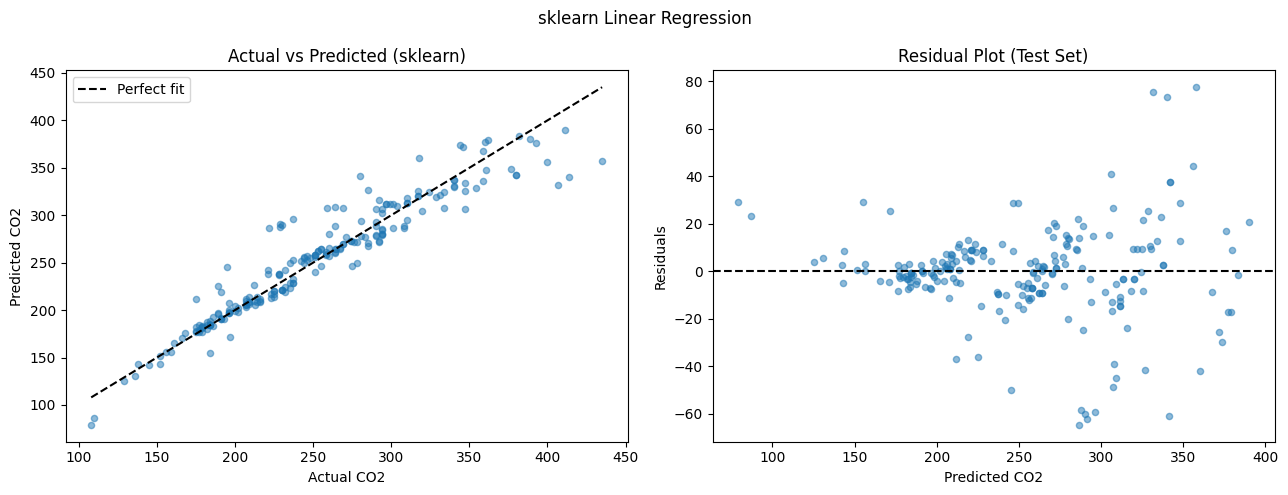

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('sklearn Linear Regression')

sk_y_pred_train = sk_model.predict(X_train)
sk_y_pred_test  = sk_model.predict(X_test)

# Actual vs Predicted
ax = axes[0]
ax.scatter(y_test, sk_y_pred_test, alpha=0.5, s=20)
lo, hi = y_test.min(), y_test.max()
ax.plot([lo, hi], [lo, hi], 'k--', lw=1.5, label='Perfect fit')
ax.set_xlabel('Actual CO2')
ax.set_ylabel('Predicted CO2')
ax.set_title('Actual vs Predicted (sklearn)')
ax.legend()

# Residuals
ax = axes[1]
residuals = y_test - sk_y_pred_test
ax.scatter(sk_y_pred_test, residuals, alpha=0.5, s=20)
ax.axhline(0, color='black', linestyle='--', lw=1.5)
ax.set_xlabel('Predicted CO2')
ax.set_ylabel('Residuals')
ax.set_title('Residual Plot (Test Set)')

plt.tight_layout()
plt.show()

<a id='5'></a>
## 5. Method 2 – Ordinary Least Squares (OLS) from Scratch

### 📐 The Math

We want to minimise the **Sum of Squared Residuals**:

$$\text{SSR} = \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 = \sum_{i=1}^{n}(y_i - (wx_i + b))^2$$

Taking partial derivatives and setting them to zero gives the closed-form solution:

$$w = \frac{\sum(x_i - \bar{x})(y_i - \bar{y})}{\sum(x_i - \bar{x})^2} = \frac{\text{Cov}(x,y)}{\text{Var}(x)}$$

$$b = \bar{y} - w\bar{x}$$

In **matrix form**: $\hat{\beta} = (X^TX)^{-1}X^Ty$

In [18]:
class OLSLinearRegression:

    def __init__(self):
        self.beta = None

    def fit(self, X, y):
        X_b = np.c_[np.ones(len(X)), X]          
        self.beta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        return self

    def predict(self, X):
        X_b = np.c_[np.ones(len(X)), X]
        return X_b @ self.beta


In [19]:
ols = OLSLinearRegression()
ols.fit(X_train, y_train)

In [20]:
feat_names = X.columns.tolist()
print(f'  Intercept: {ols.beta[0]:.4f}')
for feat, coef in zip(feat_names, ols.beta[1:]):
    print(f'  {feat}: {coef:.4f}')

print('\nsklearn vs OLS coefficients match:', 
      np.allclose(sk_model.coef_, ols.beta[1:], atol=1e-6))

  Intercept: 0.0001
  MODELYEAR: 0.1304
  ENGINESIZE: 8.9612
  CYLINDERS: 7.2402
  FUELCONSUMPTION_CITY: -13.0016
  FUELCONSUMPTION_HWY: -5.4722
  FUELCONSUMPTION_COMB: 21.8670
  FUELCONSUMPTION_COMB_MPG: -4.0345

sklearn vs OLS coefficients match: False


In [21]:
ols_y_pred_train = ols.predict(X_train)
ols_y_pred_test  = ols.predict(X_test)

ols_train_metrics = get_metrics(y_train, ols_y_pred_train, 'OLS - Train')
ols_test_metrics  = get_metrics(y_test,  ols_y_pred_test,  'OLS - Test')


── OLS - Train ──
  MSE  :  455.837
  RMSE :   21.350
  MAE  :   14.097
  R²   :   0.8854

── OLS - Test ──
  MSE  :  399.419
  RMSE :   19.985
  MAE  :   12.901
  R²   :   0.9034


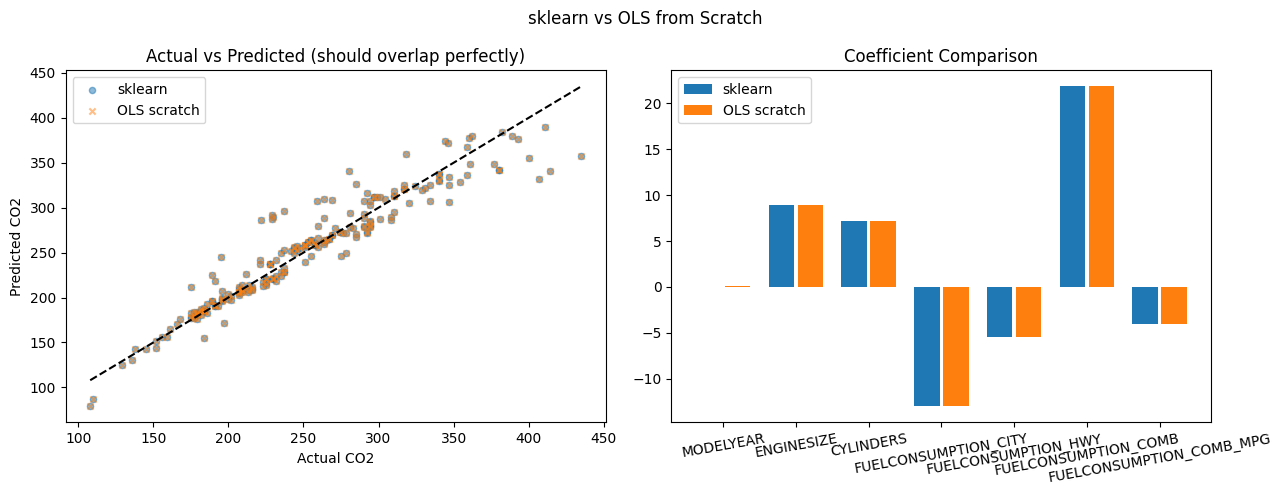

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('sklearn vs OLS from Scratch')

# Actual vs Predicted comparison
ax = axes[0]
ax.scatter(y_test, sk_y_pred_test,  alpha=0.5, s=20, label='sklearn')
ax.scatter(y_test, ols_y_pred_test, alpha=0.5, s=20, marker='x', label='OLS scratch')
lo, hi = y_test.min(), y_test.max()
ax.plot([lo, hi], [lo, hi], 'k--', lw=1.5)
ax.set_xlabel('Actual CO2')
ax.set_ylabel('Predicted CO2')
ax.set_title('Actual vs Predicted (should overlap perfectly)')
ax.legend()

# Coefficient comparison
ax = axes[1]
feat_names = X.columns.tolist()
x_pos = np.arange(len(feat_names))
ax.bar(x_pos - 0.2, sk_model.coef_,  0.35, label='sklearn')
ax.bar(x_pos + 0.2, ols.beta[1:],    0.35, label='OLS scratch')
ax.set_xticks(x_pos)
ax.set_xticklabels(feat_names, rotation=10)
ax.set_title('Coefficient Comparison')
ax.legend()

plt.tight_layout()
plt.show()

### 💡 Why OLS gives the same answer as sklearn

| | OLS (formula) | sklearn |
|---|---|---|
| **Method** | $w = \text{Cov}(x,y)/\text{Var}(x)$ | LAPACK `dgelsd` (SVD) |
| **Complexity** | $O(n)$ for simple LR | $O(np^2)$ for $p$ features |
| **Guaranteed minimum?** | ✅ Global minimum | ✅ Global minimum |
| **Requires feature scaling?** | ❌ No | ❌ No |

Both find the **exact same global minimum** of the squared-error loss — they're just different computational routes.

<a id='6'></a>
## 6. Method 3 – Gradient Descent from Scratch

### 📐 The Math

**Loss function (MSE):**
$$J(w, b) = \frac{1}{n}\sum_{i=1}^{n}(y_i - (wx_i+b))^2$$

**Gradients:**
$$\frac{\partial J}{\partial w} = \frac{-2}{n}\sum x_i(y_i - \hat{y}_i), \quad \frac{\partial J}{\partial b} = \frac{-2}{n}\sum (y_i - \hat{y}_i)$$

**Update rule:**
$$w \leftarrow w - \alpha \cdot \frac{\partial J}{\partial w}, \quad b \leftarrow b - \alpha \cdot \frac{\partial J}{\partial b}$$

where $\alpha$ is the **learning rate**.

In [23]:
class GradientDescentLR:

    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr           = learning_rate
        self.n_iter       = n_iterations
        self.w            = None
        self.b            = 0.0
        self.loss_history = []

    def fit(self, X, y):
        n, p = X.shape
        self.w = np.zeros(p)
        self.b = 0.0
        for _ in range(self.n_iter):
            y_hat = X @ self.w + self.b
            error = y_hat - y
            dw = (2/n) * X.T @ error
            db = (2/n) * error.sum()
            self.w -= self.lr * dw
            self.b -= self.lr * db
            self.loss_history.append(np.mean(error**2))
        return self

    def predict(self, X):
        return X @ self.w + self.b


In [24]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Intentionally use limited iterations (500) to show GD hasn't fully converged
gd = GradientDescentLR(learning_rate=0.1, n_iterations=500)
gd.fit(X_train_sc, y_train)

print(f'GD weights    : {gd.w}')
print(f'GD intercept  : {gd.b:.4f}')
print(f'Final MSE     : {gd.loss_history[-1]:.3f}')
print(f'\nNote: sklearn R2 = {r2_score(y_test, sk_y_pred_test):.4f} -- compare after GD metrics')

GD weights    : [  0.          12.75148434  12.88228248  -3.95756172  10.69575515
   1.81817641 -29.172754  ]
GD intercept  : 257.2567
Final MSE     : 456.269

Note: sklearn R2 = 0.9034 -- compare after GD metrics


In [25]:
# ── GD Metrics ───────────────────────────────────────────────────────────────
gd_y_pred_train = gd.predict(X_train_sc)
gd_y_pred_test  = gd.predict(X_test_sc)

gd_train_metrics = get_metrics(y_train, gd_y_pred_train, 'Gradient Descent — Train')
gd_test_metrics  = get_metrics(y_test,  gd_y_pred_test,  'Gradient Descent — Test')


── Gradient Descent — Train ──
  MSE  :  456.269
  RMSE :   21.360
  MAE  :   14.112
  R²   :   0.8853

── Gradient Descent — Test ──
  MSE  :  399.049
  RMSE :   19.976
  MAE  :   12.919
  R²   :   0.9035


c:\Users\rajak\anaconda3\envs\ocr_venv\lib\site-packages\numpy\_core\_methods.py:52: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\rajak\anaconda3\envs\ocr_venv\lib\site-packages\numpy\_core\_methods.py:52: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
C:\Users\rajak\AppData\Local\Temp\ipykernel_6112\2423035979.py:15: RuntimeWarning: overflow encountered in matmul
  y_hat = X @ self.w + self.b


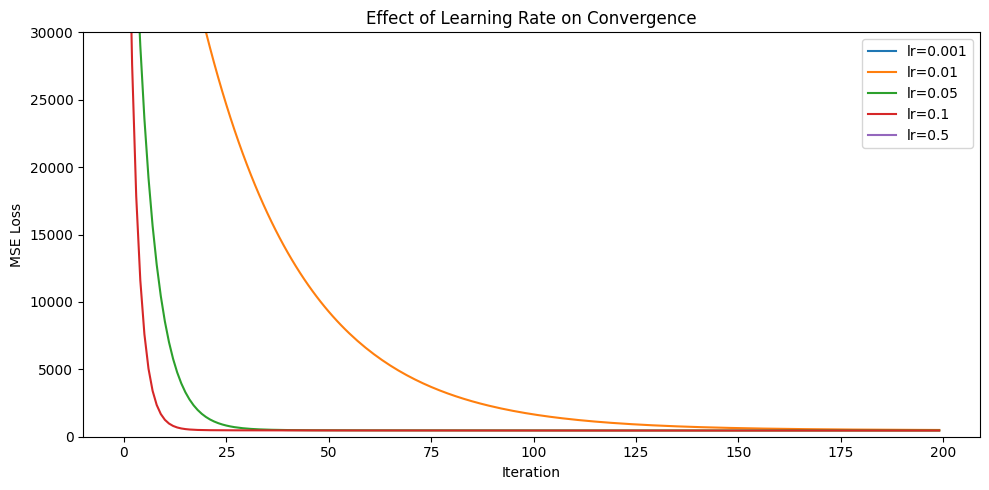

Large LR -> oscillation/divergence | Small LR -> slow convergence


In [26]:
lrs = [0.001, 0.01, 0.05, 0.1, 0.5]
fig, ax = plt.subplots(figsize=(10, 5))

for lr in lrs:
    model_tmp = GradientDescentLR(learning_rate=lr, n_iterations=500)
    model_tmp.fit(X_train_sc, y_train)
    ax.plot(model_tmp.loss_history[:200], label=f'lr={lr}')

ax.set_xlabel('Iteration')
ax.set_ylabel('MSE Loss')
ax.set_title('Effect of Learning Rate on Convergence')
ax.legend()
ax.set_ylim(0, 30000)
plt.tight_layout()
plt.show()
print('Large LR -> oscillation/divergence | Small LR -> slow convergence')

<a id='7'></a>
## 7. Head-to-Head Comparison

In [27]:
results = pd.DataFrame({
    'Method': ['sklearn', 'OLS (scratch)', 'Gradient Descent'],
    'MSE (test)':  [sk_test_metrics['MSE'],  ols_test_metrics['MSE'],  gd_test_metrics['MSE']],
    'RMSE (test)': [sk_test_metrics['RMSE'], ols_test_metrics['RMSE'], gd_test_metrics['RMSE']],
    'MAE (test)':  [sk_test_metrics['MAE'],  ols_test_metrics['MAE'],  gd_test_metrics['MAE']],
    'R2 (test)':   [sk_test_metrics['R2'],   ols_test_metrics['R2'],   gd_test_metrics['R2']],
}).set_index('Method').round(4)

print('=== Test Set Metrics Comparison ===')
results

=== Test Set Metrics Comparison ===


,MSE (test),RMSE (test),MAE (test),R2 (test)
Method,,,,
sklearn,399.4187,19.9855,12.9014,0.9034
OLS (scratch),399.4187,19.9855,12.9014,0.9034
Gradient Descent,399.0494,19.9762,12.9194,0.9035


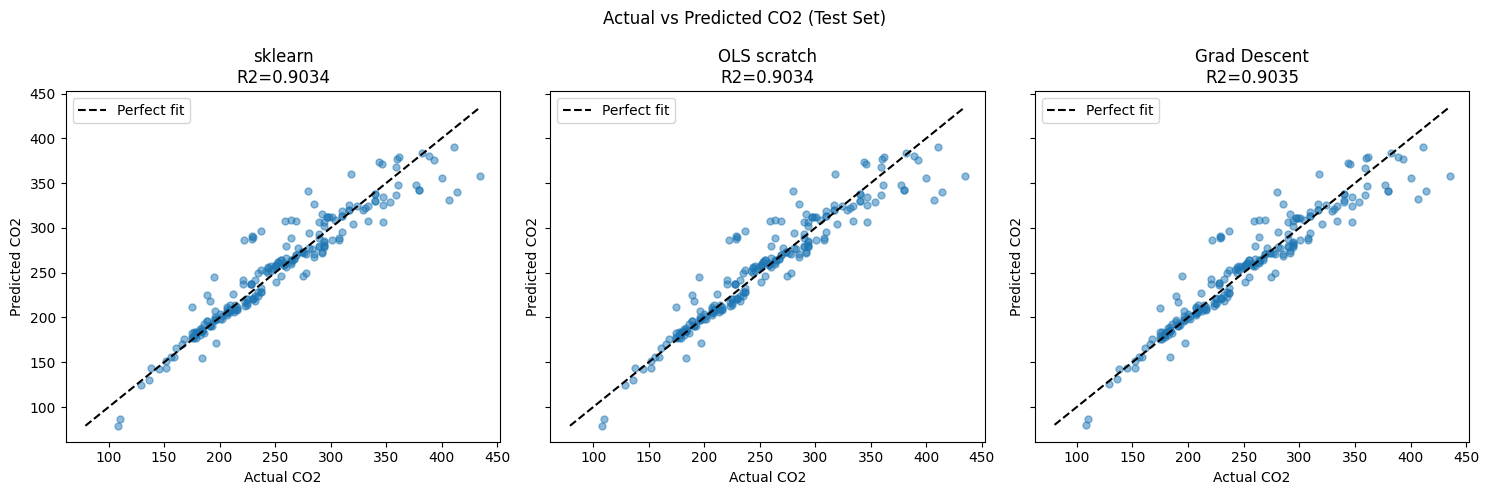

In [28]:
data_triples = [
    (sk_y_pred_test,  'sklearn'),
    (ols_y_pred_test, 'OLS scratch'),
    (gd_y_pred_test,  'Grad Descent'),
]
metrics_list = [sk_test_metrics, ols_test_metrics, gd_test_metrics]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
fig.suptitle('Actual vs Predicted CO2 (Test Set)')

for ax, (y_pred, label), metrics in zip(axes, data_triples, metrics_list):
    ax.scatter(y_test, y_pred, alpha=0.5, s=25)
    lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1.5, label='Perfect fit')
    ax.set_xlabel('Actual CO2')
    ax.set_ylabel('Predicted CO2')
    ax.set_title(f'{label}\nR2={metrics["R2"]:.4f}')
    ax.legend()

plt.tight_layout()
plt.show()